In [55]:
import pandas as pd

session_summary = pd.read_csv("datas/session_summary.csv")


In [57]:
features = session_summary[
    [
        "visit_count",
        "unique_domains",
        "unique_categories",
        "duration_minutes",
        "entertainment_ratio",
        "learning_ratio",
        "productivity_ratio",
        "researching_ratio",
        "search_ratio",
        "shopping_ratio",
        "switching_ratio"
    ]
].copy()


In [58]:
features

,visit_count,unique_domains,unique_categories,duration_minutes,entertainment_ratio,learning_ratio,productivity_ratio,researching_ratio,search_ratio,shopping_ratio,switching_ratio
0,23,6,5,10.716667,0.260870,0.347826,0.173913,0.000000,0.173913,0.043478,0.318182
1,5,2,2,9.766667,0.800000,0.000000,0.000000,0.000000,0.200000,0.000000,0.250000
2,68,3,3,73.783333,0.000000,0.882353,0.000000,0.044118,0.073529,0.000000,0.179104
3,9,1,1,0.733333,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
4,44,2,2,24.050000,0.000000,0.977273,0.000000,0.000000,0.022727,0.000000,0.023256
5,6,3,2,0.950000,0.666667,0.000000,0.000000,0.000000,0.333333,0.000000,0.600000
6,3,2,2,0.316667,0.666667,0.000000,0.000000,0.000000,0.333333,0.000000,0.500000
7,13,2,1,14.783333,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,1,1,1,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,1,1,1,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

In [60]:
from sklearn.cluster import KMeans

wcss = []

for i in range(2,19):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

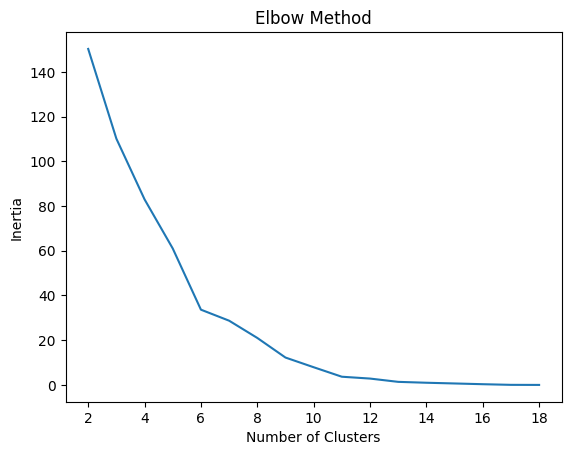

In [62]:
import matplotlib.pyplot as plt

plt.plot(range(2,19), wcss)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

In [63]:
from sklearn.metrics import silhouette_score


sil = []

for i in range(2,19):
    model = KMeans(n_clusters=i)
    result = model.fit_predict(scaled_features)
    sil.append(silhouette_score(scaled_features, result))

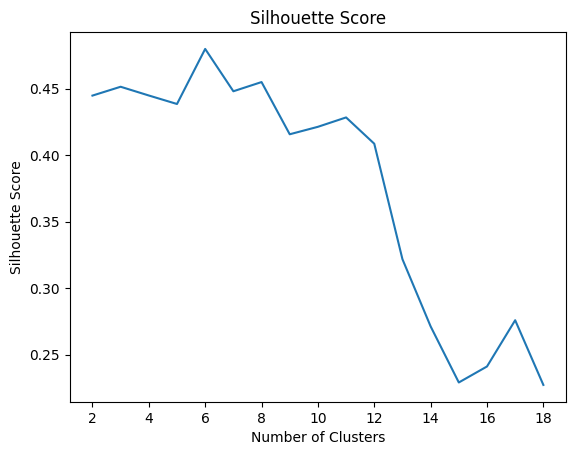

In [64]:
plt.plot(range(2, 19), sil)

plt.title("Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [ ]:
##6 is best cluster

In [65]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

session_summary["cluster"] = kmeans.fit_predict(scaled_features)

session_summary[["session_id", "cluster"]].head()

,session_id,cluster
0,1,2
1,2,3
2,3,1
3,4,5
4,5,1


In [66]:
category_columns = [
    "entertainment_ratio",
    "learning_ratio",
    "productivity_ratio",
    "researching_ratio",
    "search_ratio",
    "shopping_ratio"
]

feature_columns = [
    "visit_count",
    "duration_minutes",
    "switching_ratio"
] + category_columns

cluster_summary = (
    session_summary
    .groupby("cluster")[feature_columns]
    .mean()
    .round(2)
)

cluster_summary

,visit_count,duration_minutes,switching_ratio,entertainment_ratio,learning_ratio,productivity_ratio,researching_ratio,search_ratio,shopping_ratio
cluster,,,,,,,,,
0,5.64,9.27,0.03,0.98,0.00,0.00,0.00,0.02,0.00
1,74.00,52.47,0.09,0.17,0.78,0.00,0.01,0.04,0.00
2,27.00,11.41,0.33,0.15,0.50,0.09,0.06,0.15,0.05
3,5.25,3.90,0.42,0.68,0.00,0.00,0.00,0.32,0.00
4,37.00,38.62,0.31,0.19,0.14,0.24,0.08,0.19,0.16
5,9.00,0.73,0.00,0.00,0.00,0.00,1.00,0.00,0.00


In [68]:
cluster_labels = {
    0: "Entertainment-focused sessions",
    1: "Long learning sessions",
    2: "Mixed browsing with learning focus",
    3: "Short entertainment and search sessions",
    4: "Diverse, frequent browsing sessions",
    5: "Researching-focused short sessions"
}

session_summary["cluster_label"] = (
    session_summary["cluster"].map(cluster_labels)
)

clustered_data=session_summary[
    ["session_id", "cluster", "cluster_label"]
]

clustered_data.head()


,session_id,cluster,cluster_label
0,1,2,Mixed browsing with learning focus
1,2,3,Short entertainment and search sessions
2,3,1,Long learning sessions
3,4,5,Researching-focused short sessions
4,5,1,Long learning sessions


In [69]:
session_summary.to_csv(
    "datas/clustered_data.csv",
    index=False
)